# Exploratory Data Analysis (EDA)
## Financial Dataset

### Project Overview
This notebook presents an exploratory data analysis of a fictional financial dataset covering the period from January 2021 to December 2025.

### Objectives
- Understand the structure and characteristics of the dataset.
- Analyze financial distributions and trends.
- Identify patterns and potential anomalies.
- Explore relationships between financial variables.
- Extract business insights to support decision-making.

### Tools and Libraries
Python, Pandas, NumPy, Matplotlib and Seaborn.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
# Load processed financial dataset

df = pd.read_csv("../../data/processed/monthly_financial_summary.csv")

# Display confirmation
print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


Dataset loaded successfully!
Number of rows: 60
Number of columns: 5


In [4]:
# Display the first five rows
df.head()

,month,revenue_brl,expenses_brl,transaction_count,net_result_brl
0,2021-01,"426,964.42","266,213.94",88,"160,750.48"
1,2021-02,"452,016.28","103,504.03",63,"348,512.25"
2,2021-03,"619,251.03","102,676.67",84,"516,574.36"
3,2021-04,"440,111.23","137,998.18",75,"302,113.05"
4,2021-05,"435,205.88","176,460.42",74,"258,745.46"


## 1. Dataset Structure and Overview

This section examines the dataset structure, including column names, data types, and general information about the available variables.

In [5]:
# Dataset dimensions
print(f"Total records: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset information:")
df.info()

Total records: 60
Total columns: 5

Column names:
['month', 'revenue_brl', 'expenses_brl', 'transaction_count', 'net_result_brl']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   month              60 non-null     str    
 1   revenue_brl        60 non-null     float64
 2   expenses_brl       60 non-null     float64
 3   transaction_count  60 non-null     int64  
 4   net_result_brl     60 non-null     float64
dtypes: float64(3), int64(1), str(1)
memory usage: 2.5 KB


In [6]:
# Descriptive statistics for numerical variables
df.describe()

,revenue_brl,expenses_brl,transaction_count,net_result_brl
count,60.00,60.00,60.00,60.00
mean,"526,923.99","226,262.79",82.27,"300,661.21"
std,"102,693.90","66,565.75",8.81,"105,668.57"
min,"315,430.35","102,676.67",62.00,"72,739.33"
25%,"446,584.95","183,207.38",75.00,"232,891.72"
50%,"512,485.14","213,105.28",83.00,"313,076.36"
75%,"594,469.97","265,058.21",88.25,"365,390.04"
max,"896,328.88","428,223.15",100.00,"568,830.70"


In [8]:
# Descriptive statistics for categorical variables
df.describe(include='str')

,month
count,60
unique,60
top,2021-01
freq,1


In [9]:
# Check dataset data types
print(df.dtypes)

month                    str
revenue_brl          float64
expenses_brl         float64
transaction_count      int64
net_result_brl       float64
dtype: object


In [10]:
# Convert month column to datetime format
df['month'] = pd.to_datetime(df['month'], format='%Y-%m')

# Verify conversion
print(df.dtypes)

month                datetime64[us]
revenue_brl                 float64
expenses_brl                float64
transaction_count             int64
net_result_brl              float64
dtype: object


In [11]:
# Check chronological order and date range

print("First month:", df['month'].min())
print("Last month:", df['month'].max())

print("\nFirst 10 records:")
display(df[['month']].head(10))

print("\nLast 10 records:")
display(df[['month']].tail(10))

# Check chronological ordering
print("\nChronologically ordered:", df['month'].is_monotonic_increasing)

First month: 2021-01-01 00:00:00
Last month: 2025-12-01 00:00:00

First 10 records:


,month
0,2021-01-01
1,2021-02-01
2,2021-03-01
3,2021-04-01
4,2021-05-01
5,2021-06-01
6,2021-07-01
7,2021-08-01
8,2021-09-01
9,2021-10-01



Last 10 records:


,month
50,2025-03-01
51,2025-04-01
52,2025-05-01
53,2025-06-01
54,2025-07-01
55,2025-08-01
56,2025-09-01
57,2025-10-01
58,2025-11-01
59,2025-12-01



Chronologically ordered: True


## 2. Financial Performance Analysis

This section evaluates the overall financial performance of the business by analyzing revenue, expenses, net results, and profitability indicators.

The objective is to understand the financial performance throughout the analyzed period and identify relevant patterns that may support business decisions.

In [15]:
# Calculate overall financial indicators

total_revenue = df['revenue_brl'].sum()
total_expenses = df['expenses_brl'].sum()
total_net_result = df['net_result_brl'].sum()

average_monthly_revenue = df['revenue_brl'].mean()
average_monthly_expenses = df['expenses_brl'].mean()
average_monthly_net_result = df['net_result_brl'].mean()

# Calculate overall net profit margin
net_profit_margin = (total_net_result / total_revenue) * 100

# Display results
print("FINANCIAL PERFORMANCE SUMMARY")
print("-" * 40)

print(f"Total Revenue: R$ {total_revenue:,.2f}")
print(f"Total Expenses: R$ {total_expenses:,.2f}")
print(f"Total Net Result: R$ {total_net_result:,.2f}")

print("\nMONTHLY AVERAGES")
print("-" * 40)

print(f"Average Monthly Revenue: R$ {average_monthly_revenue:,.2f}")
print(f"Average Monthly Expenses: R$ {average_monthly_expenses:,.2f}")
print(f"Average Monthly Net Result: R$ {average_monthly_net_result:,.2f}")

print("\nPROFITABILITY")
print("-" * 40)

print(f"Overall Net Profit Margin: {net_profit_margin:.2f}%")

FINANCIAL PERFORMANCE SUMMARY
----------------------------------------
Total Revenue: R$ 31,615,439.54
Total Expenses: R$ 13,575,767.20
Total Net Result: R$ 18,039,672.34

MONTHLY AVERAGES
----------------------------------------
Average Monthly Revenue: R$ 526,923.99
Average Monthly Expenses: R$ 226,262.79
Average Monthly Net Result: R$ 300,661.21

PROFITABILITY
----------------------------------------
Overall Net Profit Margin: 57.06%


In [16]:
# Calculate monthly financial indicators

monthly_performance = df[
    ['month', 'revenue_brl', 'expenses_brl', 'net_result_brl']
].copy()

# Calculate monthly net profit margin
monthly_performance['net_margin_pct'] = (
    monthly_performance['net_result_brl'] /
    monthly_performance['revenue_brl']
) * 100

# Display first records
monthly_performance.head(10)

,month,revenue_brl,expenses_brl,net_result_brl,net_margin_pct
0,2021-01-01,"426,964.42","266,213.94","160,750.48",37.65
1,2021-02-01,"452,016.28","103,504.03","348,512.25",77.10
2,2021-03-01,"619,251.03","102,676.67","516,574.36",83.42
3,2021-04-01,"440,111.23","137,998.18","302,113.05",68.64
4,2021-05-01,"435,205.88","176,460.42","258,745.46",59.45
5,2021-06-01,"358,386.21","285,646.88","72,739.33",20.30
6,2021-07-01,"515,236.13","195,440.87","319,795.26",62.07
7,2021-08-01,"603,402.04","170,901.99","432,500.05",71.68
8,2021-09-01,"440,156.21","261,484.78","178,671.43",40.59
9,2021-10-01,"580,457.50","206,424.69","374,032.81",64.44


In [17]:
# Best and worst financial performance months

best_month = monthly_performance.loc[
    monthly_performance['net_result_brl'].idxmax()
]

worst_month = monthly_performance.loc[
    monthly_performance['net_result_brl'].idxmin()
]

print("BEST FINANCIAL PERFORMANCE")
print("-" * 40)
print(f"Month: {best_month['month'].strftime('%Y-%m')}")
print(f"Net Result: R$ {best_month['net_result_brl']:,.2f}")

print("\nWORST FINANCIAL PERFORMANCE")
print("-" * 40)
print(f"Month: {worst_month['month'].strftime('%Y-%m')}")
print(f"Net Result: R$ {worst_month['net_result_brl']:,.2f}")

BEST FINANCIAL PERFORMANCE
----------------------------------------
Month: 2024-03
Net Result: R$ 568,830.70

WORST FINANCIAL PERFORMANCE
----------------------------------------
Month: 2021-06
Net Result: R$ 72,739.33


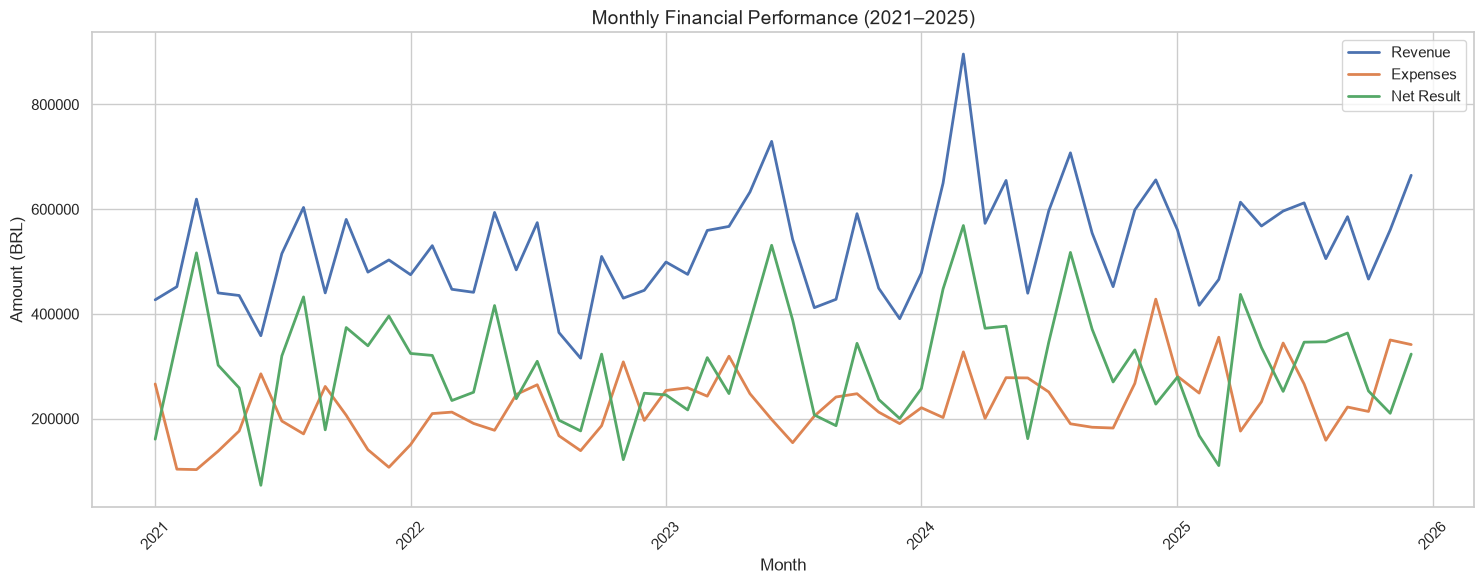

In [18]:
# Monthly financial performance visualization

plt.figure(figsize=(15, 6))

plt.plot(
    df['month'],
    df['revenue_brl'],
    label='Revenue',
    linewidth=2
)

plt.plot(
    df['month'],
    df['expenses_brl'],
    label='Expenses',
    linewidth=2
)

plt.plot(
    df['month'],
    df['net_result_brl'],
    label='Net Result',
    linewidth=2
)

plt.title('Monthly Financial Performance (2021–2025)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Amount (BRL)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 3. Annual Financial Performance Analysis

This section compares the financial performance across the five-year period.

The analysis focuses on annual revenue, expenses, net results, transaction volumes, and net profit margins to identify long-term trends and changes in financial performance.

In [19]:
# Annual financial performance analysis

annual_performance = (
    df.assign(year=df['month'].dt.year)
    .groupby('year')
    .agg(
        months_analyzed=('month', 'nunique'),
        total_revenue_brl=('revenue_brl', 'sum'),
        total_expenses_brl=('expenses_brl', 'sum'),
        total_net_result_brl=('net_result_brl', 'sum'),
        total_transactions=('transaction_count', 'sum')
    )
    .reset_index()
)

# Calculate annual net profit margin
annual_performance['net_margin_pct'] = (
    annual_performance['total_net_result_brl'] /
    annual_performance['total_revenue_brl']
) * 100

# Display annual results
annual_performance

,year,months_analyzed,total_revenue_brl,total_expenses_brl,total_net_result_brl,total_transactions,net_margin_pct
0,2021,12,"5,854,141.23","2,154,514.66","3,699,626.57",974,63.20
1,2022,12,"5,610,774.71","2,449,720.59","3,161,054.12",977,56.34
2,2023,12,"6,277,347.92","2,771,897.56","3,505,450.36",993,55.84
3,2024,12,"7,257,548.59","3,009,184.90","4,248,363.69",1007,58.54
4,2025,12,"6,615,627.09","3,190,449.49","3,425,177.60",985,51.77


In [20]:
# Identify the best and worst financial years

best_year = annual_performance.loc[
    annual_performance['total_net_result_brl'].idxmax()
]

worst_year = annual_performance.loc[
    annual_performance['total_net_result_brl'].idxmin()
]

print("BEST FINANCIAL YEAR")
print("-" * 40)
print(f"Year: {int(best_year['year'])}")
print(f"Revenue: R$ {best_year['total_revenue_brl']:,.2f}")
print(f"Net Result: R$ {best_year['total_net_result_brl']:,.2f}")
print(f"Net Margin: {best_year['net_margin_pct']:.2f}%")

print("\nWORST FINANCIAL YEAR")
print("-" * 40)
print(f"Year: {int(worst_year['year'])}")
print(f"Revenue: R$ {worst_year['total_revenue_brl']:,.2f}")
print(f"Net Result: R$ {worst_year['total_net_result_brl']:,.2f}")
print(f"Net Margin: {worst_year['net_margin_pct']:.2f}%")

BEST FINANCIAL YEAR
----------------------------------------
Year: 2024
Revenue: R$ 7,257,548.59
Net Result: R$ 4,248,363.69
Net Margin: 58.54%

WORST FINANCIAL YEAR
----------------------------------------
Year: 2022
Revenue: R$ 5,610,774.71
Net Result: R$ 3,161,054.12
Net Margin: 56.34%


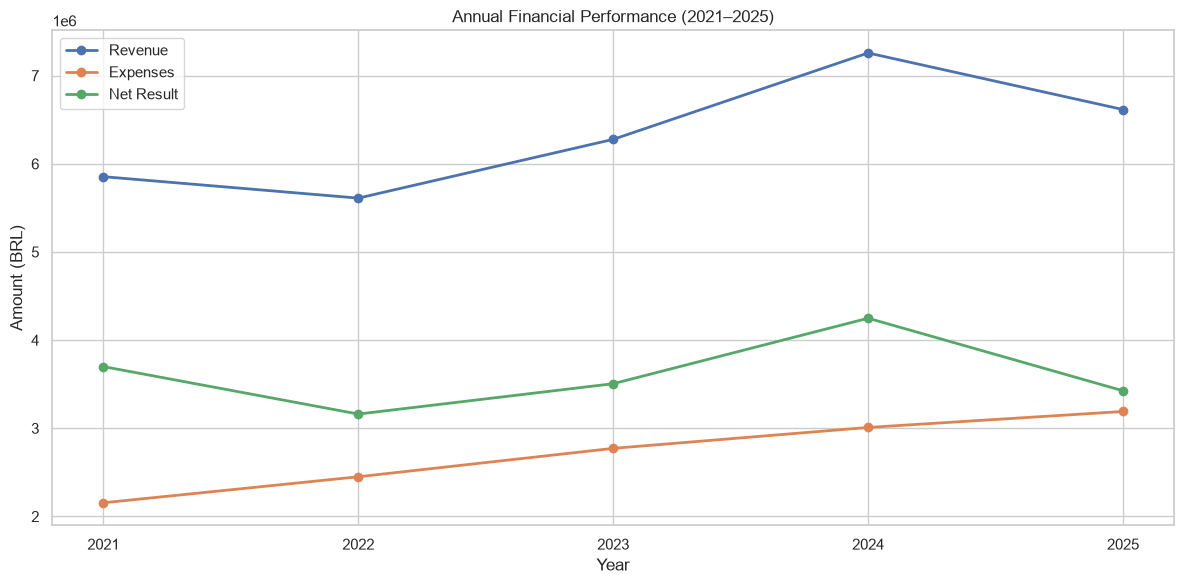

In [21]:
# Annual financial performance visualization

plt.figure(figsize=(12, 6))

plt.plot(
    annual_performance['year'],
    annual_performance['total_revenue_brl'],
    marker='o',
    linewidth=2,
    label='Revenue'
)

plt.plot(
    annual_performance['year'],
    annual_performance['total_expenses_brl'],
    marker='o',
    linewidth=2,
    label='Expenses'
)

plt.plot(
    annual_performance['year'],
    annual_performance['total_net_result_brl'],
    marker='o',
    linewidth=2,
    label='Net Result'
)

plt.title('Annual Financial Performance (2021–2025)')
plt.xlabel('Year')
plt.ylabel('Amount (BRL)')
plt.xticks(annual_performance['year'])
plt.legend()
plt.tight_layout()

plt.show()

## 4. Year-over-Year (YoY) Growth Analysis

This section evaluates the annual percentage changes in revenue, expenses, net results, and transaction volumes.

The objective is to identify growth patterns, assess financial performance over time, and understand whether expenses are increasing at a faster rate than revenue.

In [22]:
# Calculate Year-over-Year growth rates

annual_performance['revenue_growth_pct'] = (
    annual_performance['total_revenue_brl'].pct_change() * 100
)

annual_performance['expenses_growth_pct'] = (
    annual_performance['total_expenses_brl'].pct_change() * 100
)

annual_performance['net_result_growth_pct'] = (
    annual_performance['total_net_result_brl'].pct_change() * 100
)

annual_performance['transactions_growth_pct'] = (
    annual_performance['total_transactions'].pct_change() * 100
)

# Display YoY analysis
annual_performance[
    [
        'year',
        'revenue_growth_pct',
        'expenses_growth_pct',
        'net_result_growth_pct',
        'transactions_growth_pct'
    ]
].round(2)

,year,revenue_growth_pct,expenses_growth_pct,net_result_growth_pct,transactions_growth_pct
0,2021,NaN,NaN,NaN,NaN
1,2022,-4.16,13.70,-14.56,0.31
2,2023,11.88,13.15,10.89,1.64
3,2024,15.61,8.56,21.19,1.41
4,2025,-8.84,6.02,-19.38,-2.18


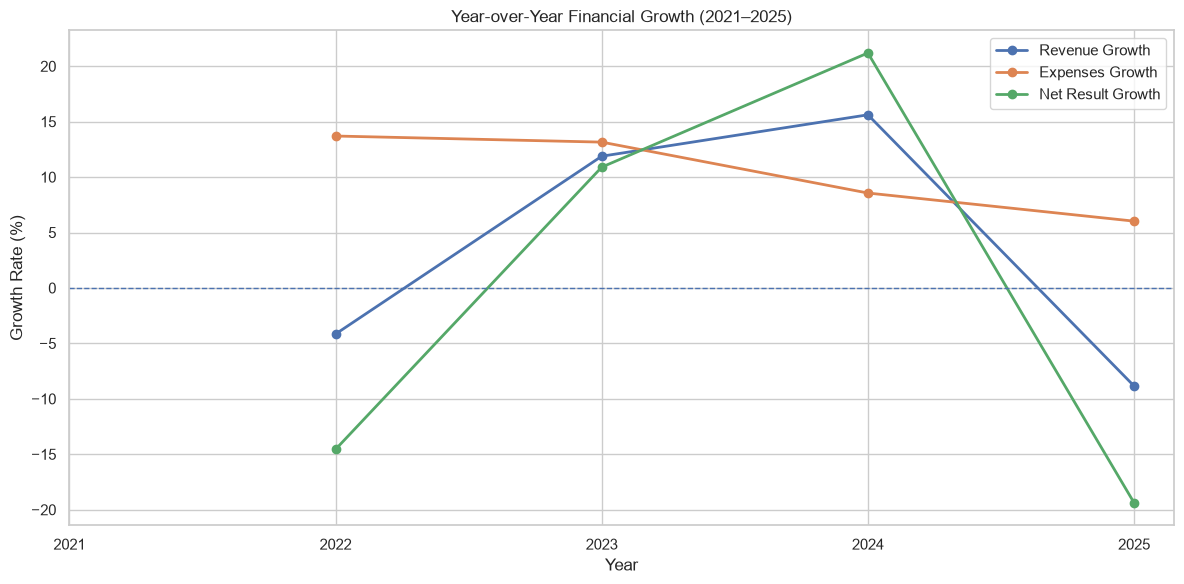

In [23]:
# Year-over-Year growth visualization

growth_columns = [
    'revenue_growth_pct',
    'expenses_growth_pct',
    'net_result_growth_pct'
]

growth_labels = [
    'Revenue Growth',
    'Expenses Growth',
    'Net Result Growth'
]

plt.figure(figsize=(12, 6))

for column, label in zip(growth_columns, growth_labels):
    plt.plot(
        annual_performance['year'],
        annual_performance[column],
        marker='o',
        linewidth=2,
        label=label
    )

plt.axhline(y=0, linestyle='--', linewidth=1)

plt.title('Year-over-Year Financial Growth (2021–2025)')
plt.xlabel('Year')
plt.ylabel('Growth Rate (%)')
plt.xticks(annual_performance['year'])
plt.legend()
plt.tight_layout()

plt.show()

## 5. Monthly Seasonality Analysis

This section investigates monthly financial patterns across the five-year period.

The objective is to identify recurring patterns in revenue, expenses, and net results, highlighting potential seasonal variations in financial performance.

In [24]:
# Monthly seasonality analysis

monthly_seasonality = (
    df.assign(
        month_number=df['month'].dt.month,
        month_name=df['month'].dt.month_name()
    )
    .groupby(['month_number', 'month_name'], as_index=False)
    .agg(
        average_revenue=('revenue_brl', 'mean'),
        average_expenses=('expenses_brl', 'mean'),
        average_net_result=('net_result_brl', 'mean'),
        average_transactions=('transaction_count', 'mean'),
        months_analyzed=('month', 'count')
    )
)

# Display monthly averages
monthly_seasonality.round(2)

,month_number,month_name,average_revenue,average_expenses,average_net_result,average_transactions,months_analyzed
0,1,January,"487,923.96","234,433.81","253,490.15",84.00,5
1,2,February,"504,860.65","204,610.15","300,250.50",75.60,5
2,3,March,"597,601.00","248,225.17","349,375.83",85.60,5
3,4,April,"527,001.31","204,943.83","322,057.48",81.40,5
4,5,May,"576,930.21","222,460.88","354,469.33",81.60,5
5,6,June,"521,610.60","270,476.48","251,134.12",85.40,5
6,7,July,"568,190.99","226,256.47","341,934.52",89.20,5
7,8,August,"518,588.73","178,416.90","340,171.83",77.80,5
8,9,September,"464,741.36","209,489.83","255,251.53",78.80,5
9,10,October,"520,056.47","207,271.59","312,784.88",84.00,5


In [25]:
# Rank months by average net result

monthly_ranking = monthly_seasonality.sort_values(
    by='average_net_result',
    ascending=False
)

display(
    monthly_ranking[
        [
            'month_name',
            'average_revenue',
            'average_expenses',
            'average_net_result'
        ]
    ].round(2)
)

,month_name,average_revenue,average_expenses,average_net_result
4,May,"576,930.21","222,460.88","354,469.33"
2,March,"597,601.00","248,225.17","349,375.83"
6,July,"568,190.99","226,256.47","341,934.52"
7,August,"518,588.73","178,416.90","340,171.83"
3,April,"527,001.31","204,943.83","322,057.48"
9,October,"520,056.47","207,271.59","312,784.88"
1,February,"504,860.65","204,610.15","300,250.50"
11,December,"531,962.60","252,764.85","279,197.75"
8,September,"464,741.36","209,489.83","255,251.53"
0,January,"487,923.96","234,433.81","253,490.15"


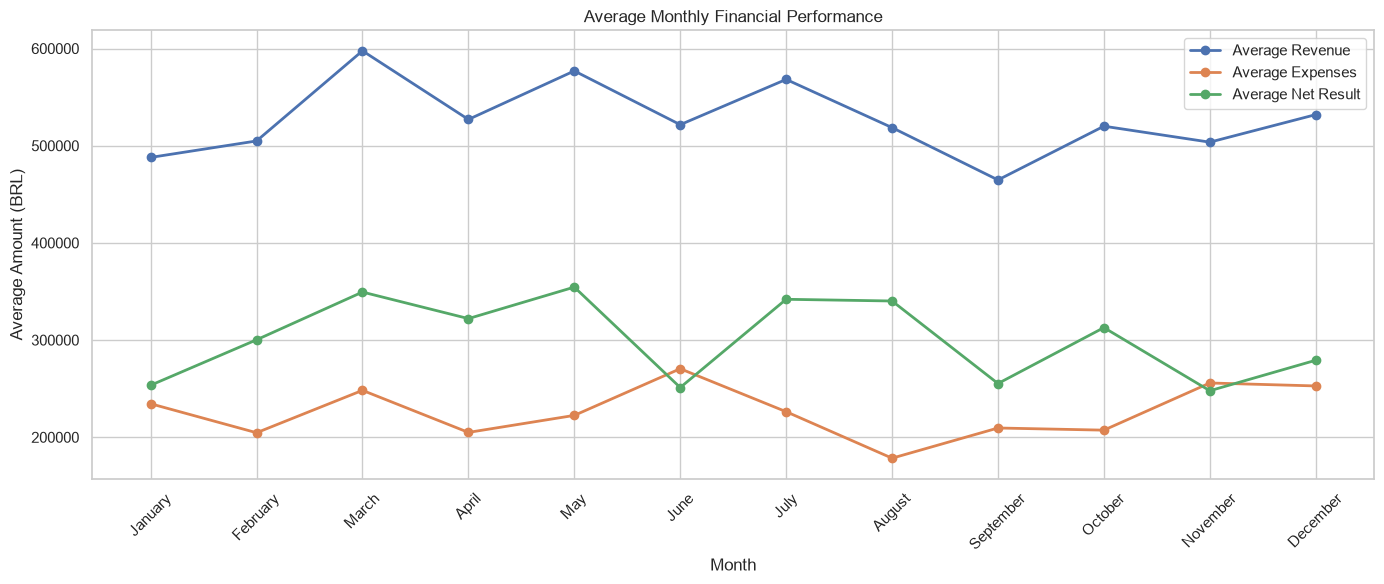

In [26]:
# Monthly seasonality visualization

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_seasonality['month_name'],
    monthly_seasonality['average_revenue'],
    marker='o',
    linewidth=2,
    label='Average Revenue'
)

plt.plot(
    monthly_seasonality['month_name'],
    monthly_seasonality['average_expenses'],
    marker='o',
    linewidth=2,
    label='Average Expenses'
)

plt.plot(
    monthly_seasonality['month_name'],
    monthly_seasonality['average_net_result'],
    marker='o',
    linewidth=2,
    label='Average Net Result'
)

plt.title('Average Monthly Financial Performance')
plt.xlabel('Month')
plt.ylabel('Average Amount (BRL)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

## 6. Correlation Analysis

This section investigates the relationships between financial variables using correlation analysis.

The objective is to identify associations between revenue, expenses, transaction volume, and net financial results.

Pearson correlation coefficients will be used to measure the strength and direction of linear relationships between numerical variables.

In [27]:
# Calculate correlation matrix

correlation_matrix = df[
    [
        'revenue_brl',
        'expenses_brl',
        'transaction_count',
        'net_result_brl'
    ]
].corr(method='pearson')

# Display correlation matrix
correlation_matrix.round(3)

,revenue_brl,expenses_brl,transaction_count,net_result_brl
revenue_brl,1.00,0.28,0.64,0.80
expenses_brl,0.28,1.00,0.54,-0.36
transaction_count,0.64,0.54,1.00,0.29
net_result_brl,0.80,-0.36,0.29,1.00


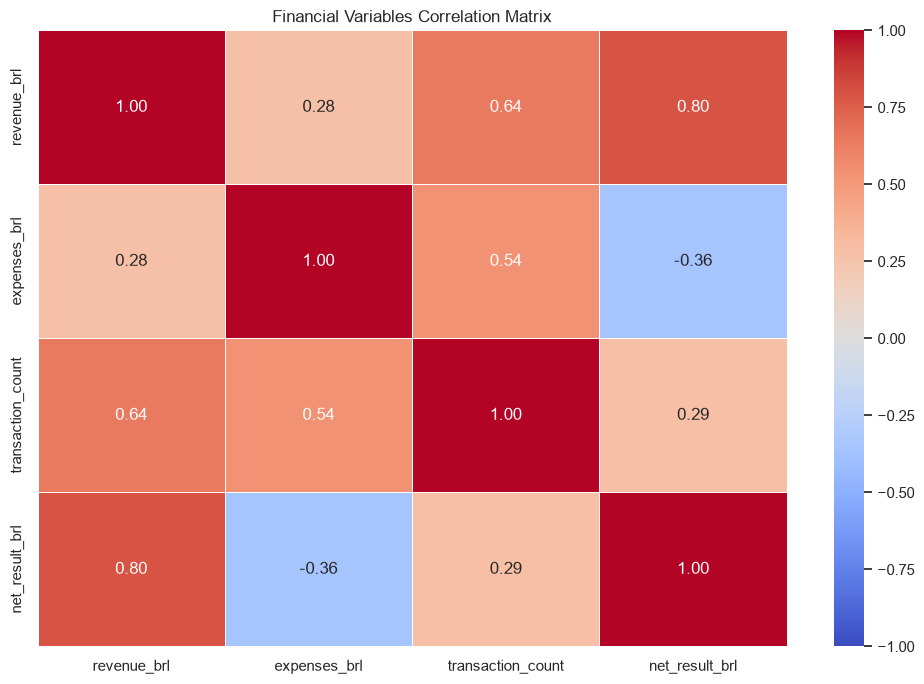

In [28]:
# Correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Financial Variables Correlation Matrix')
plt.tight_layout()

plt.show()

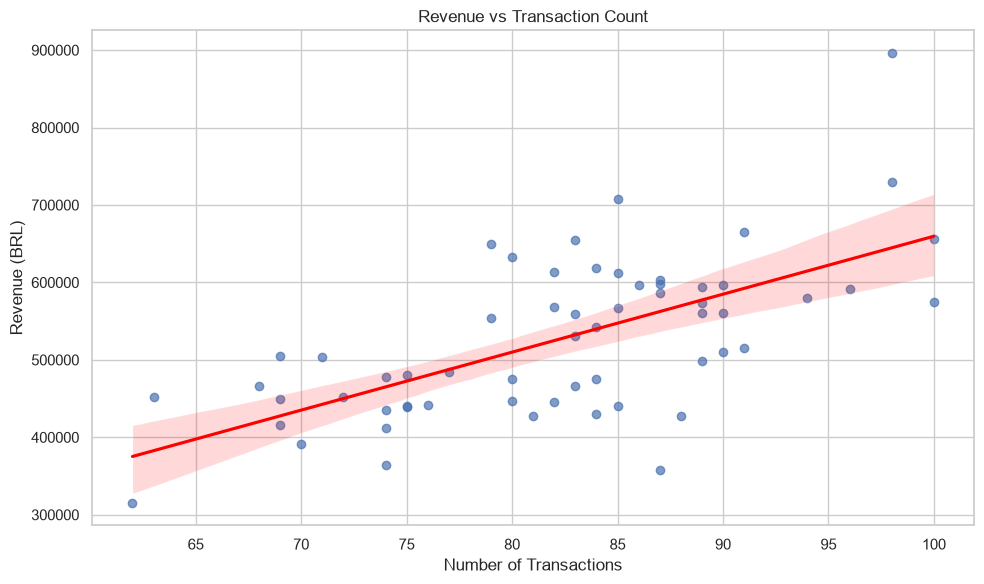

In [29]:
# Revenue vs Transaction Count

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='transaction_count',
    y='revenue_brl',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

plt.title('Revenue vs Transaction Count')
plt.xlabel('Number of Transactions')
plt.ylabel('Revenue (BRL)')

plt.tight_layout()
plt.show()

## 7. Average Transaction Value Analysis

This section examines the average revenue generated per transaction.

The objective is to understand how transaction volume and average transaction value contribute to overall revenue performance.

The analysis will also investigate monthly variations in average transaction value throughout the five-year period.

In [30]:
# Calculate average revenue per transaction

df['average_transaction_value'] = (
    df['revenue_brl'] / df['transaction_count']
)

# Display results
df[
    [
        'month',
        'revenue_brl',
        'transaction_count',
        'average_transaction_value'
    ]
].head(10)

,month,revenue_brl,transaction_count,average_transaction_value
0,2021-01-01,"426,964.42",88,"4,851.87"
1,2021-02-01,"452,016.28",63,"7,174.86"
2,2021-03-01,"619,251.03",84,"7,372.04"
3,2021-04-01,"440,111.23",75,"5,868.15"
4,2021-05-01,"435,205.88",74,"5,881.16"
5,2021-06-01,"358,386.21",87,"4,119.38"
6,2021-07-01,"515,236.13",91,"5,661.94"
7,2021-08-01,"603,402.04",87,"6,935.66"
8,2021-09-01,"440,156.21",85,"5,178.31"
9,2021-10-01,"580,457.50",94,"6,175.08"


In [31]:
# Descriptive statistics of average transaction value

df['average_transaction_value'].describe()

count      60.00
mean    6,393.49
std       936.04
min     4,119.38
25%     5,663.27
50%     6,394.21
75%     6,936.58
max     9,146.21
Name: average_transaction_value, dtype: float64

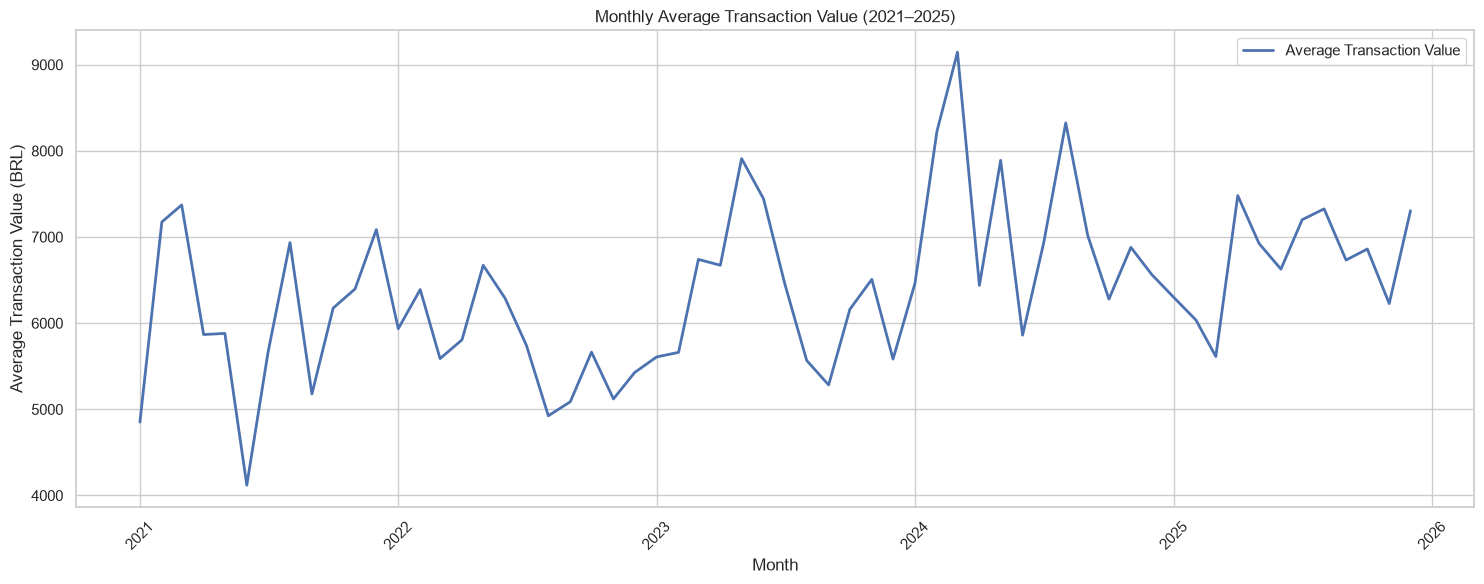

In [32]:
# Monthly average transaction value

plt.figure(figsize=(15, 6))

plt.plot(
    df['month'],
    df['average_transaction_value'],
    linewidth=2,
    label='Average Transaction Value'
)

plt.title('Monthly Average Transaction Value (2021–2025)')
plt.xlabel('Month')
plt.ylabel('Average Transaction Value (BRL)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [33]:
# Identify highest and lowest average transaction values

highest_ticket = df.loc[
    df['average_transaction_value'].idxmax()
]

lowest_ticket = df.loc[
    df['average_transaction_value'].idxmin()
]

print("HIGHEST AVERAGE TRANSACTION VALUE")
print("-" * 40)

print(f"Month: {highest_ticket['month'].strftime('%Y-%m')}")
print(f"Average Value: R$ {highest_ticket['average_transaction_value']:,.2f}")

print("\nLOWEST AVERAGE TRANSACTION VALUE")
print("-" * 40)

print(f"Month: {lowest_ticket['month'].strftime('%Y-%m')}")
print(f"Average Value: R$ {lowest_ticket['average_transaction_value']:,.2f}")

HIGHEST AVERAGE TRANSACTION VALUE
----------------------------------------
Month: 2024-03
Average Value: R$ 9,146.21

LOWEST AVERAGE TRANSACTION VALUE
----------------------------------------
Month: 2021-06
Average Value: R$ 4,119.38


### Key Findings

The Average Transaction Value analysis reveals considerable fluctuations throughout the 2021–2025 period.

March 2024 recorded the highest average transaction value, reaching R$ 9,146.21, while June 2021 presented the lowest value, at R$ 4,119.38.

These findings suggest that revenue performance is influenced not only by transaction volume but also by the average financial value generated per transaction.

Further investigation of unusually high and low observations may help identify relevant patterns in the dataset.

## 8. Outlier Detection

This section identifies potential outliers in the financial dataset using the Interquartile Range (IQR) method.

The analysis focuses on revenue, expenses, net results, transaction counts, and average transaction values.

The objective is to identify unusual observations that may require further investigation before drawing final conclusions.

In [34]:
# Outlier detection using the IQR method

variables = [
    'revenue_brl',
    'expenses_brl',
    'net_result_brl',
    'transaction_count',
    'average_transaction_value'
]

outlier_summary = []
outlier_records = []

for column in variables:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append({
        'variable': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': len(outliers)
    })

    for index in outliers.index:
        outlier_records.append({
            'month': df.loc[index, 'month'],
            'variable': column,
            'value': df.loc[index, column]
        })

# Create summary DataFrame
outlier_summary = pd.DataFrame(outlier_summary)

# Create detailed outlier DataFrame
outlier_records = pd.DataFrame(outlier_records)

# Display results
outlier_summary.round(2)

,variable,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
0,revenue_brl,"446,584.95","594,469.97","147,885.02","224,757.43","816,297.50",1
1,expenses_brl,"183,207.38","265,058.21","81,850.84","60,431.12","387,834.47",1
2,net_result_brl,"232,891.72","365,390.04","132,498.32","34,144.25","564,137.51",1
3,transaction_count,75.00,88.25,13.25,55.12,108.12,0
4,average_transaction_value,"5,663.27","6,936.58","1,273.31","3,753.30","8,846.55",1
